# Nexar Collision Prediction — Baselines and Evaluation

**Computer Vision Project**

## Goal

This notebook establishes the baseline and evaluation framework for the
collision-prediction experiments.

The notebook has four main purposes:

1. Create a reproducible temporal sampling index.
2. Establish a naive baseline.
3. Establish a classical optical-flow baseline.
4. Define the evaluation procedure that will later be used by the
   learned temporal model.

The main experimental conditions are:

- TTE = 0.5 seconds
- TTE = 1.0 seconds
- TTE = 1.5 seconds

The observation window is:

- 2 seconds

Each clip is represented using:

- 16 sampled frames

The same validation videos and temporal sampling protocol must be used
when comparing the different models.

No frames after the prediction time are allowed into a clip.

## 1. Imports

We use:

- `pandas` for metadata and experiment tables
- `numpy` for numerical operations
- `matplotlib` for visualisation
- `cv2` for video processing and optical flow
- `Path` for file paths
- `scikit-learn` for classification and evaluation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2

from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## 2. Experiment configuration

We define the important experimental parameters in one place.

This prevents different parts of the notebook from accidentally using
different settings.

In [2]:
DATA_DIR = Path("./data/raw")
PROCESSED_DIR = Path("./data/processed")
RESULTS_DIR = Path("./results")

TRAIN_DIR = DATA_DIR / "train"

TTE_VALUES = [0.5, 1.0, 1.5]

CLIP_DURATION = 2.0
NUM_FRAMES = 16

RANDOM_SEED = 42

print("TTE values:", TTE_VALUES)
print("Clip duration:", CLIP_DURATION)
print("Number of frames:", NUM_FRAMES)
print("Random seed:", RANDOM_SEED)

TTE values: [0.5, 1.0, 1.5]
Clip duration: 2.0
Number of frames: 16
Random seed: 42


## 3. Load the fixed train/validation split

Notebook 3 created the train/validation split.

We must use those saved files rather than generating a new split.

This ensures that every model is evaluated on the same videos.

In [3]:
train_df = pd.read_csv(
    PROCESSED_DIR / "train_split.csv"
)

val_df = pd.read_csv(
    PROCESSED_DIR / "val_split.csv"
)

print("Training videos:", len(train_df))
print("Validation videos:", len(val_df))

Training videos: 1200
Validation videos: 300


In [4]:
print("Training class distribution:")
print(train_df["target"].value_counts())

print("\nValidation class distribution:")
print(val_df["target"].value_counts())

Training class distribution:
target
1    600
0    600
Name: count, dtype: int64

Validation class distribution:
target
0    150
1    150
Name: count, dtype: int64


## 4. Verify that the saved split is still leakage-free

In [5]:
train_ids = set(train_df["id"])
val_ids = set(val_df["id"])

overlap = train_ids.intersection(val_ids)

print("Number of overlapping video IDs:", len(overlap))

if len(overlap) == 0:
    print("No train/validation video overlap.")
else:
    print("WARNING: overlap detected.")

Number of overlapping video IDs: 0
No train/validation video overlap.


# Part A — Reproducible Negative Sampling

Positive videos have an annotated event.

Negative videos do not.

For a positive video:

`prediction_time = event_time - TTE`

For a negative video, there is no event from which to calculate a
prediction time.

We therefore need a reproducible negative sampling strategy.

Rather than selecting completely arbitrary timestamps, we approximately
match the distribution of positive prediction times.

This reduces the possibility that a classifier learns an accidental
relationship between the time position within a video and the class
label.

## 5. Positive prediction-time distribution

For each TTE, we calculate the prediction time of every valid positive
training example.

For example:

`prediction_time = event_time - 1.0`

when TTE = 1.0 seconds.

These prediction times will provide the reference distribution for
negative sampling.

In [6]:
positive_train = train_df[
    train_df["target"] == 1
].copy()

positive_val = val_df[
    val_df["target"] == 1
].copy()

print("Positive training videos:", len(positive_train))
print("Positive validation videos:", len(positive_val))

Positive training videos: 600
Positive validation videos: 150


In [7]:
positive_prediction_times = {}

for tte in TTE_VALUES:
    prediction_times = (
        positive_train["time_of_event"] - tte
    )
    
    valid_times = prediction_times[
        prediction_times >= CLIP_DURATION
    ]
    
    positive_prediction_times[tte] = valid_times.to_numpy()
    
    print(
        f"TTE = {tte:.1f}s -> "
        f"{len(valid_times)} valid positive prediction times"
    )

TTE = 0.5s -> 600 valid positive prediction times
TTE = 1.0s -> 600 valid positive prediction times
TTE = 1.5s -> 599 valid positive prediction times


## 6. Visualise positive prediction-time distributions

Before using these distributions for negative sampling, we inspect
them.

The x-axis represents the location of the prediction point within the
video.

The distribution is different for each TTE because subtracting a
different TTE shifts the prediction time.

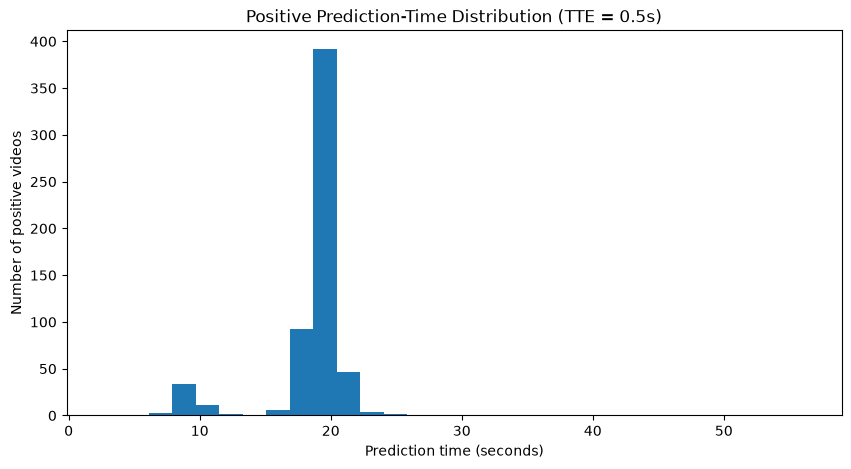

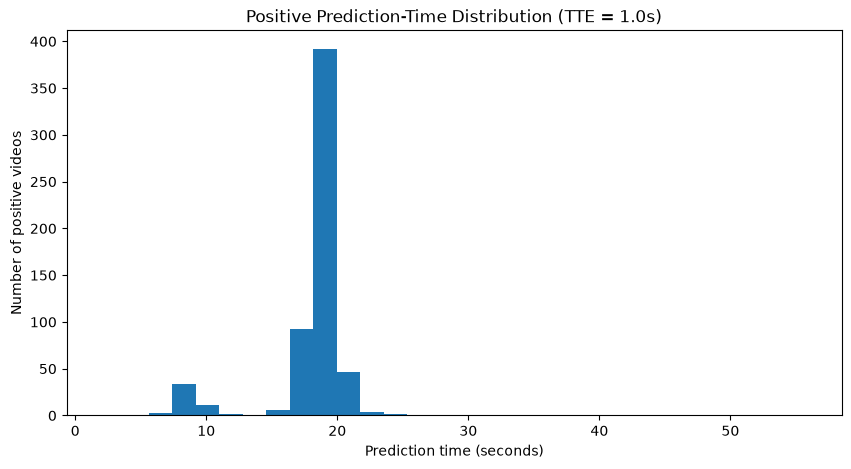

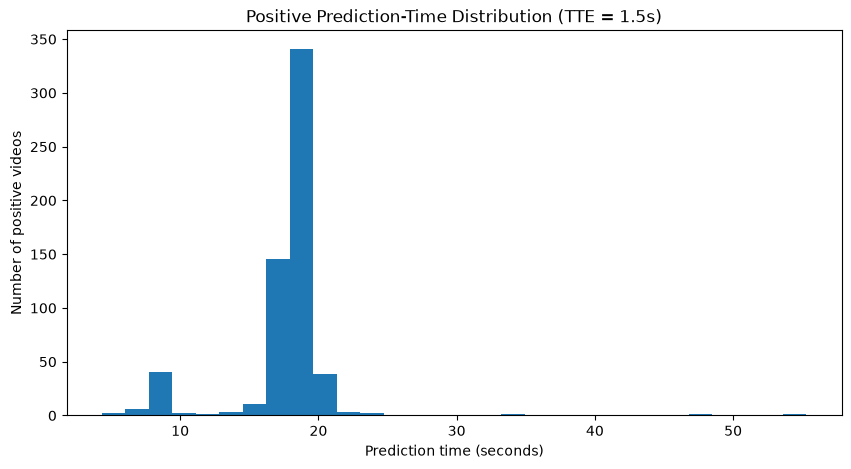

In [8]:
for tte in TTE_VALUES:
    plt.figure(figsize=(10, 5))
    
    plt.hist(
        positive_prediction_times[tte],
        bins=30
    )
    
    plt.xlabel("Prediction time (seconds)")
    plt.ylabel("Number of positive videos")
    plt.title(
        f"Positive Prediction-Time Distribution "
        f"(TTE = {tte:.1f}s)"
    )
    
    plt.show()

## 7. Negative prediction-time sampler

For every negative video, we choose a prediction time from the
corresponding positive prediction-time distribution.

The chosen time must satisfy:

`prediction_time >= CLIP_DURATION`

and:

`prediction_time <= video_duration`

A fixed random seed is used.

This means the negative sampling procedure can be reproduced.

In [9]:
def get_video_duration(video_path):
    cap = cv2.VideoCapture(str(video_path))
    
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )
    
    cap.release()
    
    if fps <= 0:
        return None
    
    return frame_count / fps

## 8. Test the duration function

In [10]:
test_negative_id = int(
    train_df[train_df["target"] == 0].iloc[0]["id"]
)

test_negative_path = (
    TRAIN_DIR / f"{test_negative_id:05d}.mp4"
)

test_duration = get_video_duration(
    test_negative_path
)

print("Video ID:", test_negative_id)
print("Duration:", test_duration)

Video ID: 1888
Duration: 40.1


## 9. Generate negative sampling metadata

Each negative video receives one prediction time for each TTE.

The resulting sampling decisions will be stored in a DataFrame.

This is important because the actual sampled times should not change
between models.

For example:

Negative video 1888:

TTE 0.5 → prediction time = ...
TTE 1.0 → prediction time = ...
TTE 1.5 → prediction time = ...

Once generated, these values become part of the experimental protocol.

In [11]:
def sample_negative_prediction_time(
    video_duration,
    reference_times,
    rng,
    clip_duration
):
    valid_reference_times = reference_times[
        reference_times <= video_duration
    ]
    
    valid_reference_times = valid_reference_times[
        valid_reference_times >= clip_duration
    ]
    
    if len(valid_reference_times) == 0:
        return None
    
    index = rng.integers(
        0,
        len(valid_reference_times)
    )
    
    return float(valid_reference_times[index])

In [12]:
rng = np.random.default_rng(RANDOM_SEED)

negative_train = train_df[
    train_df["target"] == 0
].copy()

negative_val = val_df[
    val_df["target"] == 0
].copy()

print("Negative training videos:", len(negative_train))
print("Negative validation videos:", len(negative_val))

Negative training videos: 600
Negative validation videos: 150


## 10. Create training clip index

The clip index records where each training example should be sampled.

Each row will represent one video/TTE combination.

The important columns are:

- video ID
- target
- TTE
- prediction time
- clip start
- clip end

In [13]:
train_clip_records = []

for _, row in train_df.iterrows():
    video_id = int(row["id"])
    target = int(row["target"])
    
    video_path = (
        TRAIN_DIR / f"{video_id:05d}.mp4"
    )
    
    if target == 1:
        for tte in TTE_VALUES:
            prediction_time = (
                row["time_of_event"] - tte
            )
            
            clip_start = (
                prediction_time - CLIP_DURATION
            )
            
            if clip_start < 0:
                continue
            
            train_clip_records.append({
                "id": video_id,
                "target": target,
                "tte": tte,
                "prediction_time": prediction_time,
                "clip_start": clip_start,
                "clip_end": prediction_time
            })
    
    else:
        video_duration = get_video_duration(
            video_path
        )
        
        for tte in TTE_VALUES:
            prediction_time = sample_negative_prediction_time(
                video_duration,
                positive_prediction_times[tte],
                rng,
                CLIP_DURATION
            )
            
            if prediction_time is None:
                continue
            
            clip_start = (
                prediction_time - CLIP_DURATION
            )
            
            train_clip_records.append({
                "id": video_id,
                "target": target,
                "tte": tte,
                "prediction_time": prediction_time,
                "clip_start": clip_start,
                "clip_end": prediction_time
            })

In [14]:
train_clips = pd.DataFrame(
    train_clip_records
)

print("Number of training clips:", len(train_clips))

train_clips.head()

Number of training clips: 3599


,id,target,tte,prediction_time,clip_start,clip_end
0,780,1,0.5,19.467,17.467,19.467
1,780,1,1.0,18.967,16.967,18.967
2,780,1,1.5,18.467,16.467,18.467
3,661,1,0.5,19.900,17.900,19.900
4,661,1,1.0,19.400,17.400,19.400


## 11. Create validation clip index

We repeat the same procedure for validation.

The validation sampling uses a separate random generator state, but the
same fixed seed makes the process reproducible.

The validation clip index must be saved and reused by every model.

In [15]:
rng_val = np.random.default_rng(RANDOM_SEED + 1)

val_clip_records = []

for _, row in val_df.iterrows():
    video_id = int(row["id"])
    target = int(row["target"])
    
    video_path = (
        TRAIN_DIR / f"{video_id:05d}.mp4"
    )
    
    if target == 1:
        for tte in TTE_VALUES:
            prediction_time = (
                row["time_of_event"] - tte
            )
            
            clip_start = (
                prediction_time - CLIP_DURATION
            )
            
            if clip_start < 0:
                continue
            
            val_clip_records.append({
                "id": video_id,
                "target": target,
                "tte": tte,
                "prediction_time": prediction_time,
                "clip_start": clip_start,
                "clip_end": prediction_time
            })
    
    else:
        video_duration = get_video_duration(
            video_path
        )
        
        for tte in TTE_VALUES:
            prediction_time = sample_negative_prediction_time(
                video_duration,
                positive_prediction_times[tte],
                rng_val,
                CLIP_DURATION
            )
            
            if prediction_time is None:
                continue
            
            clip_start = (
                prediction_time - CLIP_DURATION
            )
            
            val_clip_records.append({
                "id": video_id,
                "target": target,
                "tte": tte,
                "prediction_time": prediction_time,
                "clip_start": clip_start,
                "clip_end": prediction_time
            })

In [16]:
val_clips = pd.DataFrame(
    val_clip_records
)

print("Number of validation clips:", len(val_clips))

val_clips.head()

Number of validation clips: 900


,id,target,tte,prediction_time,clip_start,clip_end
0,1339,0,0.5,19.133,17.133,19.133
1,1339,0,1.0,17.633,15.633,17.633
2,1339,0,1.5,20.133,18.133,20.133
3,168,1,0.5,18.633,16.633,18.633
4,168,1,1.0,18.133,16.133,18.133


## 12. Check clip counts

Each valid video should contribute one clip for each TTE.

At TTE = 1.5 seconds, one positive training video is invalid because it
does not contain enough pre-event footage.

The validation set has no invalid positive videos.

Negative videos should have one valid sampled clip per TTE.

In [17]:
print("Training clips by TTE:")
print(
    train_clips.groupby(
        ["tte", "target"]
    ).size()
)

print("\nValidation clips by TTE:")
print(
    val_clips.groupby(
        ["tte", "target"]
    ).size()
)

Training clips by TTE:
tte  target
0.5  0         600
     1         600
1.0  0         600
     1         600
1.5  0         600
     1         599
dtype: int64

Validation clips by TTE:
tte  target
0.5  0         150
     1         150
1.0  0         150
     1         150
1.5  0         150
     1         150
dtype: int64


## 13. Check class balance for every TTE

The class distribution should remain approximately balanced.

This is especially important because the number of valid positive clips
can differ slightly at different TTE values.

In [18]:
for tte in TTE_VALUES:
    print(f"\nTTE = {tte:.1f}s")
    
    print("Training:")
    print(
        train_clips[
            train_clips["tte"] == tte
        ]["target"].value_counts()
    )
    
    print("Validation:")
    print(
        val_clips[
            val_clips["tte"] == tte
        ]["target"].value_counts()
    )


TTE = 0.5s
Training:
target
1    600
0    600
Name: count, dtype: int64
Validation:
target
0    150
1    150
Name: count, dtype: int64

TTE = 1.0s
Training:
target
1    600
0    600
Name: count, dtype: int64
Validation:
target
0    150
1    150
Name: count, dtype: int64

TTE = 1.5s
Training:
target
0    600
1    599
Name: count, dtype: int64
Validation:
target
0    150
1    150
Name: count, dtype: int64


## 14. Check temporal validity

Every clip must satisfy:

`clip_start >= 0`

and:

`clip_end = prediction_time`

No clip is allowed to extend beyond its prediction time.

This is our final automatic leakage check before the clips are used by
the models.

In [19]:
invalid_train = (
    (train_clips["clip_start"] < 0) |
    (train_clips["clip_end"] > train_clips["prediction_time"])
).sum()

invalid_val = (
    (val_clips["clip_start"] < 0) |
    (val_clips["clip_end"] > val_clips["prediction_time"])
).sum()

print("Invalid training clips:", invalid_train)
print("Invalid validation clips:", invalid_val)

Invalid training clips: 0
Invalid validation clips: 0


## 15. Save the temporal sampling protocol

The clip indices are now part of the experimental dataset definition.

Saving them means that future models do not have to regenerate the
negative timestamps.

Every model can therefore use exactly the same clips.

In [20]:
PROCESSED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

train_clips.to_csv(
    PROCESSED_DIR / "train_clips.csv",
    index=False
)

val_clips.to_csv(
    PROCESSED_DIR / "val_clips.csv",
    index=False
)

print("Saved clip sampling metadata.")

Saved clip sampling metadata.


# Part B — Evaluation

All models will produce a probability:

`P(positive)`

rather than only a hard class label.

For example:

`0.92` means the model assigns a high probability to the positive
class.

Using probabilities allows us to evaluate the ranking quality of the
model using metrics such as Average Precision.

The primary metric for this project will be:

**Average Precision (AP)**

Additional metrics will include:

- ROC-AUC
- precision
- recall
- F1
- confusion matrix

## 16. Create an evaluation function